In [128]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.metrics import roc_curve, auc, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.linear_model import LogisticRegression

In [129]:
data_df = pd.read_csv('../data/corona_tested_individuals.english.csv', low_memory=False)

In [130]:
data_df.head()

,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-11-12,0,0,0,0,0,negative,No,male,Other
1,2020-11-12,0,1,0,0,0,negative,No,male,Other
2,2020-11-12,0,0,0,0,0,negative,Yes,female,Other
3,2020-11-12,0,0,0,0,0,negative,No,male,Other
4,2020-11-12,0,1,0,0,0,negative,No,male,Contact with confirmed


In [131]:
from datetime import datetime

data_df['test_date'] = data_df.apply(lambda r:datetime.strptime(r['test_date'],"%Y-%m-%d").timestamp(), axis=1)

In [132]:
data_df.shape

(2742596, 10)

In [133]:
data_df['gender'].unique()

array(['male', 'female', nan], dtype=object)

In [134]:
data_df = data_df.dropna().copy()

In [135]:
data_df['corona_result'].unique()

array(['negative', 'positive', 'other'], dtype=object)

In [136]:
data_df['test_indication'].unique()

array(['Other', 'Contact with confirmed', 'Abroad'], dtype=object)

In [137]:
data_df['test_indication_c'] = data_df.apply(lambda r:1 if r['test_indication']=="Contact with confirmed" else 0, axis=1)

In [138]:
data_df['test_indication_a'] = data_df.apply(lambda r:1 if r['test_indication']=="Abroad" else 0, axis=1)

In [139]:
one_dict = {'No':0,'Yes':1}
data_df['age+60'] = data_df['age_60_and_above'].map(one_dict)

sex_dict = {'male':0, 'female':1}
data_df['sex'] = data_df['gender'].map(sex_dict)

second_dict = {'positive':1, 'negative':0 }
data_df['result'] = data_df['corona_result'].map(second_dict)

In [140]:
data_df = data_df.dropna().copy()

In [157]:
X = data_df[['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache', 'age+60', 'sex', 'test_indication_c', 'test_indication_a']]

In [158]:
y = data_df['result']

In [159]:
y.unique()

array([0., 1.])

In [160]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [161]:
model = LogisticRegression()
model.fit(X_train, y_train)
y_test_pred = model.predict_proba(X_test)[:,1]

In [162]:
fpr,tpr,thresholds = roc_curve(y_test, y_test_pred)

score_df = pd.DataFrame()

score_df['fallout'] = fpr
score_df['sensitivity'] = tpr
score_df['threshold'] = thresholds

score_df.head()

roc_auc = auc(score_df['fallout'],score_df['sensitivity'])
roc_auc

0.8140842299960817

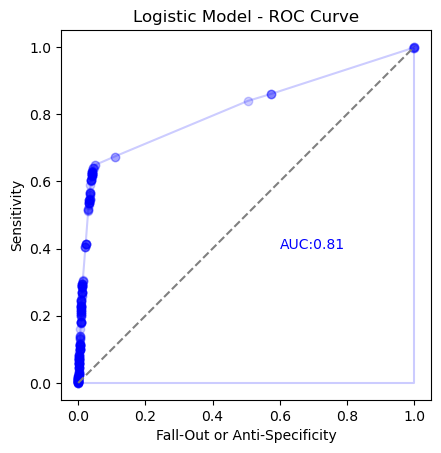

In [163]:
plt.axes().set_aspect('equal')

plt.plot(fpr,tpr,'-o',color='blue',alpha=0.2)
plt.plot([0,1,1],[0,0,1],'-',color='blue',alpha=0.2)
plt.plot([0,1],[0,1],'--',color='grey')

plt.title('Logistic Model - ROC Curve')
plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')

plt.text(0.6,0.4,"AUC:{0:.2f}".format(roc_auc),color='blue')

plt.show()

In [164]:
model.coef_

array([[ 0.62927437,  1.68812439,  1.30480994,  1.49328971,  1.87703966,
         0.13691369, -0.19653208,  2.76896022, -0.68895204]])

In [165]:
X.columns

Index(['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache',
       'age+60', 'sex', 'test_indication_c', 'test_indication_a'],
      dtype='object')

In [ ]:
data_df = data_df[['cough', 'fever', 'sore_throat', 'shortness_of_breath',
       'head_ache', 'corona_result', 'age_60_and_above', 'gender',
       'test_indication']]

In [ ]:
for column in data_df.columns:
    print('column:{}'.format(column))
    print(data_df[column].unique())

In [ ]:
# Binarisation de la colonne 'test_indication'

In [ ]:
data_df['test_indication_o'] = data_df.apply(lambda x:1 if x['test_indication']=='Other' else 0, axis=1)
data_df['test_indication_c'] = data_df.apply(lambda x:1 if x['test_indication']=='Contact with confirmed' else 0, axis=1)
data_df['test_indication_a'] = data_df.apply(lambda x:1 if x['test_indication']=='Abroad' else 0, axis=1)

In [ ]:
one_dict = {'Yes':1, 'No':0, 'positive':1, 'negative':0, 'male':1, 'female':0 }

data_df['is_a_male'] = data_df['gender'].map(one_dict)
data_df['is_above_60']  = data_df['age_60_and_above'].map(one_dict)
data_df['target'] = data_df['corona_result'].map(one_dict)

In [ ]:
data_df['target'].unique()

In [ ]:
data_df.head()

In [ ]:
data_df[(data_df['test_indication_c']==1)|(data_df['test_indication_a']==1)].shape

In [ ]:
# Dans la suite, nous ne considérerons que les colonnes numériques et nous laisserons tomber 'test_indication_o' (une colonne sur les trois... sinon, on a une singularité!!!)

In [ ]:
X = data_df.drop(['target','corona_result','age_60_and_above','gender','test_indication','test_indication_o'],axis=1)
y = data_df['target']

In [ ]:
X.shape

In [ ]:
X.columns

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [ ]:
model = sm.Logit(y_train, add_constant((X_train)))
 
results = model.fit()

In [ ]:
results.summary()

In [ ]:
y_pred_train = results.predict(add_constant(X_train))
y_pred_test = results.predict(add_constant(X_test))

In [ ]:
fpr,tpr,thresholds = roc_curve(y_test,y_pred_test)

score_df = pd.DataFrame()

score_df['fallout'] = fpr
score_df['sensitivity'] = tpr
score_df['threshold'] = thresholds

score_df.head()

roc_auc = auc(score_df['fallout'],score_df['sensitivity'])
roc_auc

In [ ]:
plt.figure(figsize=(cm2inch(15), cm2inch(15)))
plt.axes().set_aspect('equal')

plt.plot(fpr,tpr,'-',color='blue',alpha=0.2)
plt.plot([0,1,1],[0,0,1],'-',color='blue',alpha=0.2)
plt.plot([0,1],[0,1],'--',color='grey')

plt.title('Logistic Model - ROC Curve')
plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')

plt.text(0.6,0.4,"AUC:{0:.2f}".format(roc_auc),color='blue')

plt.show()

In [ ]:
score_df['dist_to_diag'] = abs(score_df['fallout']-score_df['sensitivity'])

In [ ]:
score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]

In [ ]:
opt_threshold = score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]['threshold'].values[0]
print('optimal_threshold:{}'.format(opt_threshold))

opt_fallout = score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]['fallout'].values[0]
opt_sensitivity = score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]['sensitivity'].values[0]

In [ ]:
plt.figure(figsize=(cm2inch(15), cm2inch(15)))
plt.axes().set_aspect('equal')

plt.plot(fpr,tpr,'-',color='blue',alpha=0.2)
plt.plot([0,1,1],[0,0,1],'-',color='blue',alpha=0.2)
plt.plot([0,1],[0,1],'--',color='grey')

plt.title('Logistic Model - ROC Curve')
plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')

plt.text(0.6,0.4,"AUC:{0:.2f}".format(roc_auc),color='blue')

plt.show()

In [ ]:
plt.figure(figsize=(cm2inch(15), cm2inch(15)))
plt.axes().set_aspect('equal')

plt.plot(score_df['fallout'],score_df['sensitivity'],'-o',alpha=0.2)

plt.plot([0,1],[0,1],'--',color='grey')
plt.plot([(opt_fallout+opt_sensitivity)/2,opt_fallout],[(opt_fallout+opt_sensitivity)/2,opt_sensitivity],'--',color='grey')
plt.scatter(x=[(opt_fallout+opt_sensitivity)/2,opt_fallout],y=[(opt_fallout+opt_sensitivity)/2,opt_sensitivity],marker='o',color='green')
plt.plot([0,1-opt_sensitivity+opt_fallout],[opt_sensitivity-opt_fallout,1],'--',color='grey')

plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')
plt.show()

In [ ]:
score_df = pd.DataFrame()
score_df['y'] = y_test
score_df['y_pred'] = y_test_pred
score_df['y_pred_bin'] = score_df['y_pred'].apply(lambda x:0 if x<0.5 else 1)

In [ ]:
print('Classification report(test):\n{}'.format(classification_report(score_df['y'],score_df['y_pred_bin'])))

In [ ]:
cm = confusion_matrix(score_df['y'],score_df['y_pred_bin'])
cm

In [ ]:
diag_prop = (cm[0][0]+cm[1][1])/np.sum(cm)
diag_prop

In [ ]:
#
# Au threshold optimal:
#

In [ ]:
score_df = pd.DataFrame()
score_df['y'] = y_test
score_df['y_pred'] = y_test_pred
score_df['y_pred_bin'] = score_df['y_pred'].apply(lambda x:0 if x<opt_threshold else 1)

In [ ]:
print('Classification report(test):\n{}'.format(classification_report(score_df['y'],score_df['y_pred_bin'])))

In [ ]:
cm = confusion_matrix(score_df['y'],score_df['y_pred_bin'])
cm

In [ ]:
diag_prop = (cm[0][0]+cm[1][1])/np.sum(cm)
diag_prop

In [ ]:
#
# Feature selection
#

In [ ]:
ordered_features = []
remaining_features = X.columns

optimal_auc_df = pd.DataFrame()

for iter in range(0,X.columns.size):
    print('remaining_features:{}'.format(remaining_features))

    auc_df = pd.DataFrame()

    for feature in remaining_features:
        updated_ordered_features = ordered_features.copy()
        updated_ordered_features.append(feature)
        print('updated_ordered_features:{}'.format(updated_ordered_features))
        projected_X = X[updated_ordered_features]
        
        model = sm.Logit(y, add_constant(projected_X))
        results = model.fit(disp=False)
        y_pred = results.predict(add_constant(projected_X))
        
        data_df['pred']      = y_pred
        data_df['churnFlag'] = y
        
        fpr,tpr,thresholds = roc_curve(data_df['churnFlag'],data_df['pred'])
        
        score_df = pd.DataFrame()
        
        score_df['fallout']     = fpr
        score_df['sensitivity'] = tpr
        score_df['T']           = thresholds
        
        roc_auc = auc(score_df['fallout'],score_df['sensitivity'])
        
        print('iter:{}: feature:{} => auc:{}'.format(iter,feature,roc_auc))
    
        auc_df = pd.concat([auc_df,pd.DataFrame({'feature':[feature],'auc':[roc_auc]})])
        
    opt_feature = auc_df.sort_values(by='auc', ascending=False).iloc[0]['feature']
    opt_auc     = auc_df.sort_values(by='auc', ascending=False).iloc[0]['auc']
    print('\niter:{} opt_feature:{} opt_auc:{}\n'.format(iter, opt_auc, opt_feature))
          
    optimal_auc_df = pd.concat([optimal_auc_df, pd.DataFrame({'feature':[opt_feature],'auc':[opt_auc]})])
    
    remaining_features = np.delete(remaining_features, np.where(remaining_features == opt_feature))
    ordered_features.append(opt_feature)

In [ ]:
optimal_auc_df

In [ ]:
plt.plot(optimal_auc_df['feature'],optimal_auc_df['auc'],'o-')
plt.ylabel('AUC')
plt.xticks(rotation='vertical')
plt.show()

In [ ]:
plt.plot(optimal_auc_df['feature'],optimal_auc_df['auc'],'o-')
plt.ylabel('AUC')
plt.xticks(rotation='vertical')
plt.ylim(bottom=0.5)
plt.show()

In [ ]:
#
# Decision Tree
#

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.tree import export_text

In [ ]:
model = DecisionTreeClassifier(max_depth=5, random_state=42)
 
results = model.fit(X_train,y_train)
pred_y_test = results.predict(X_test)

print('Classification report:{}'.format(classification_report(y_test,pred_y_test)))

In [ ]:
X_train.head()

In [ ]:
plot_tree(model, feature_names = X.columns, filled = True)
plt.show()

In [ ]:
tree_rule = export_text(model, feature_names = list(X.columns), show_weights=True)
print(tree_rule)

In [ ]:
#
# plotROC
#

In [ ]:
def plot_ROC(model, X, y, model_name='', plot=True):
        
    y_proba = model.predict(X)
    
    fpr, tpr, thresholds = roc_curve(y,y_proba)
        
    roc_auc = roc_auc_score(y,y_proba)
    
    if plot==True:
        score_df = pd.DataFrame()
        
        score_df['fallout'] = fpr
        score_df['sensitivity'] = tpr
        score_df['T'] = thresholds
        
        def cm2inch(value):
            return value/2.54
        
        plt.figure(figsize=(cm2inch(15), cm2inch(15)))
        plt.axes().set_aspect('equal')
        
        plt.plot(fpr,tpr,'-',color='blue',alpha=0.2)
        plt.plot([0,1,1],[0,0,1],'-',color='blue',alpha=0.2)
        plt.plot([0,1],[0,1],'--',color='grey')
        
        plt.title('{:} - ROC Curve'.format(model_name))
        plt.xlabel('Fall-Out or Anti-Specificity')
        plt.ylabel('Sensitivity')
    
        plt.text(0.6,0.4,"AUC:{0:.2f}".format(roc_auc),color='blue')
        
        plt.show()
    
    return roc_auc

In [ ]:
#
# Deep Learning
#

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
input_shape = (X.shape[1], )
#normalizer = keras.layers.Normalization(axis=-1)
normalizer = tf.keras.layers.experimental.preprocessing.Normalization(axis=-1)
normalizer.adapt(np.array(X_train))

model = keras.Sequential(
    [
        normalizer,
        
        layers.Dense(64, activation='relu'),
        layers.Dense(8, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(8, activation='relu'),
        layers.Dense(64, activation='relu'),
        #layers.Dense(32, activation='relu'),
        #layers.Dense(16, activation='relu'),
        #layers.Dense(8, activation='relu'),       
        layers.Dense(4, activation='relu'),
    
        layers.Dense(1, activation='sigmoid'),
    ]
)

model.summary()

In [ ]:
# entrainement du modèle
batch_size = 16*16
epochs = 5

model.compile(loss='binary_crossentropy', optimizer=keras.optimizers.Adam(0.001), metrics=['accuracy'])

history = model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

In [ ]:
y_train_pred = model.predict(X_train)

In [ ]:
y_test_pred = model.predict(X_test)

In [ ]:
y_test_pred

In [ ]:
plot_ROC(model, X_train, y_train)

In [ ]:
plot_ROC(model, X_test, y_test)

In [ ]:
fpr,tpr,thresholds = roc_curve(y_test,y_pred_test)

score_df = pd.DataFrame()

score_df['fallout'] = fpr
score_df['sensitivity'] = tpr
score_df['threshold'] = thresholds

score_df.head()

roc_auc = auc(score_df['fallout'],score_df['sensitivity'])
roc_auc

In [ ]:
score_df['dist_to_diag'] = abs(score_df['fallout']-score_df['sensitivity'])

opt_threshold = score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]['threshold'].values[0]
print('optimal_threshold:{}'.format(opt_threshold))

opt_fallout = score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]['fallout'].values[0]
opt_sensitivity = score_df[score_df['dist_to_diag']==np.max(score_df['dist_to_diag'])]['sensitivity'].values[0]

In [ ]:
plt.figure(figsize=(cm2inch(15), cm2inch(15)))
plt.axes().set_aspect('equal')

plt.plot(score_df['fallout'],score_df['sensitivity'],'-o',alpha=0.2)

plt.plot([0,1],[0,1],'--',color='grey')
plt.plot([(opt_fallout+opt_sensitivity)/2,opt_fallout],[(opt_fallout+opt_sensitivity)/2,opt_sensitivity],'--',color='grey')
plt.scatter(x=[(opt_fallout+opt_sensitivity)/2,opt_fallout],y=[(opt_fallout+opt_sensitivity)/2,opt_sensitivity],marker='o',color='green')
plt.plot([0,1-opt_sensitivity+opt_fallout],[opt_sensitivity-opt_fallout,1],'--',color='grey')

plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')
plt.show()

In [ ]:
score_df = pd.DataFrame()
score_df['y'] = y_test
score_df['y_pred'] = y_test_pred
score_df['y_pred_bin'] = score_df['y_pred'].apply(lambda x:0 if x<opt_threshold else 1)

In [ ]:
print('Classification report (test)\n:{}'.format(classification_report(score_df['y'],score_df['y_pred_bin'])))

In [ ]:
cm = confusion_matrix(score_df['y'],score_df['y_pred_bin'])
cm

In [ ]:
diag_prop = (cm[0][0]+cm[1][1])/(np.sum(cm))
diag_prop